<a href="https://colab.research.google.com/github/dltnwjd06/2026.Linear/blob/main/hw.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### 라이브러리 선언

In [1440]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon

INF = 1000  # 그림판 크기
LEN = 100   # 처음 사각형의 크기

### 축 그리기 및 사각형 그리기

In [1441]:
def draw_axis(ax):
  ax.axhline(0, color='black', alpha=0.3)  # x-axis line
  ax.axvline(0, color='black', alpha=0.3)  # y-axis line
  ax.set_xlim(-INF, INF)
  ax.set_ylim(-INF, INF)
  ax.set_aspect('equal')  # 정사각형 모양으로 backboard 그리기

In [1442]:
def draw_rectangle(ax, p1, p2, p3, p4):
  my_polygon = Polygon([p1, p2, p3, p4])
  ax.add_patch(my_polygon)

In [1443]:
def draw_object(ax):
  p1 = np.array([0, 0])
  p2 = np.array([LEN, 0])
  p3 = np.array([LEN, LEN])
  p4 = np.array([0, LEN])

  draw_rectangle(ax, p1, p2, p3, p4)

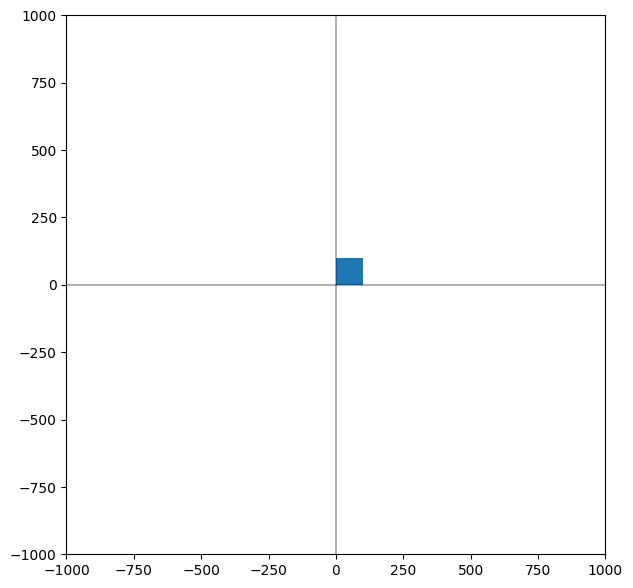

In [1444]:
# 그림판 선언 및 크기 설정
fig, ax = plt.subplots(figsize=(7,7))

# 축 그리기
draw_axis(ax)

# 물체 그리기
draw_object(ax)

plt.show()

### 본론
#### 1. 변환 구현
* translate(p, dx, dy)
* rotate(p, theta)  
* scale(p, sx, sy)  
* shear_x(p, sx)  
* shear_y(p, sy)  
* reflect_x(p)  
* reflect_y(p)   
* ...

In [1445]:
# 점 p를 x축 방향으로 dx만큼, y축 방향으로 dy만큼 이동시킨 점 q를 구할 것
# q = T(dx, dy) p1
def translate(p, dx, dy):
  # 1. 동차좌표계 (homogeneous coordinate)으로 변환
  hp = np.array([p[0], p[1], 1.0])

  # 2. 이동 변환 행렬 생성
  m = np.array([[1.0, 0.0, dx], [0.0, 1.0, dy], [0.0, 0.0, 1.0]])

  # 3. 행렬과 벡터의 곱
  q = np.dot(m, hp)  # (3,3) x (3,1) -> (3,1)
  #print(q)

  # 4. 2차원 좌표계로 변환
  q = np.array([q[0], q[1]])
  return q

In [1446]:
def scale(p, sx, sy) :
  hp = np.array([p[0], p[1], 1.0])
  m = np
  m = np.array([[sx, 0.0, 0.0], [0.0, sy, 0.0], [0.0, 0.0, 1.0]])
  q = np.dot(m, hp)
  q = np.array([q[0], q[1]])
  return q

In [1447]:
def rotate(p, theta) :
  hp = np.array([p[0], p[1], 1.0])
  m = np.array([[np.cos(theta), -np.sin(theta), 0.0], [np.sin(theta), np.cos(theta), 0.0], [0.0, 0.0, 1.0]])
  q = np.dot(m, hp)
  q = np.array([q[0], q[1]])
  return q

In [1448]:
def shear_x(p, shx):
  """x축 방향 밀림 변환 (Horizontal Shear)"""
  hp = np.array([p[0], p[1], 1.0])
  m = np.array([[1.0, shx, 0.0], [0.0, 1.0, 0.0], [0.0, 0.0, 1.0]])
  q = np.dot(m, hp)
  return np.array([q[0], q[1]])

In [1449]:
def shear_y(p, shy):
  """y축 방향 밀림 변환 (Vertical Shear)"""
  hp = np.array([p[0], p[1], 1.0])
  m = np.array([[1.0, 0.0, 0.0], [shy, 1.0, 0.0], [0.0, 0.0, 1.0]])
  q = np.dot(m, hp)
  return np.array([q[0], q[1]])

In [1450]:
def reflect_x(p):
  """x축 대칭 반전 (Reflection across x-axis, 상하 반전)"""
  hp = np.array([p[0], p[1], 1.0])
  m = np.array([[1.0, 0.0, 0.0], [0.0, -1.0, 0.0], [0.0, 0.0, 1.0]])
  q = np.dot(m, hp)
  return np.array([q[0], q[1]])

In [1451]:
def reflect_y(p):
  """y축 대칭 반전 (Reflection across y-axis, 좌우 반전)"""
  hp = np.array([p[0], p[1], 1.0])
  m = np.array([[-1.0, 0.0, 0.0], [0.0, 1.0, 0.0], [0.0, 0.0, 1.0]])
  q = np.dot(m, hp)
  return np.array([q[0], q[1]])

In [1452]:
def reflect_origin(p):
  """원점 대칭 반전 (Reflection across Origin)"""
  hp = np.array([p[0], p[1], 1.0])
  m = np.array([[-1.0, 0.0, 0.0], [0.0, -1.0, 0.0], [0.0, 0.0, 1.0]])
  q = np.dot(m, hp)
  return np.array([q[0], q[1]])

#### 2. 파트 그리기
* draw_cockpit(p1, p2, p3, p4)    # 중앙 조종석
* draw_left_arm(p1, p2, p3, p4)   # 왼쪽 날개축
* draw_left_wing(p1, p2, p3, p4)  # 왼쪽 날개
* draw_right_arm(p1, p2, p3, p4)  # 오른쪽 날개축
* draw_right_wing(p1, p2, p3, p4) # 오른쪽 날개

In [1453]:
def draw_cockpit(ax, p1, p2, p3, p4):  # 중앙 조종석
  # 1. 사각형을 원점으로 이동 변환: T(-LEN/2, -LEN/2)
  # q = T(-LEN/2, -LEN/2)p
  q1 = translate(p1, -LEN/2, -LEN/2)
  q2 = translate(p2, -LEN/2, -LEN/2)
  q3 = translate(p3, -LEN/2, -LEN/2)
  q4 = translate(p4, -LEN/2, -LEN/2)


  # 2. 크기 변환: S(5, 5)
  s = 5
  q1 = scale(q1, s, s)
  q2 = scale(q2, s, s)
  q3 = scale(q3, s, s)
  q4 = scale(q4, s, s)

  # 3. 회전 변환: R(pi/4)
  q1 = rotate(q1, 3.14/4.0)
  q2 = rotate(q2, 3.14/4.0)
  q3 = rotate(q3, 3.14/4.0)
  q4 = rotate(q4, 3.14/4.0)


  # 4. polygon 그리기
  draw_rectangle(ax, q1, q2, q3, q4)

In [1454]:
def draw_left_arm(ax, p1, p2, p3, p4):
  q1 = translate(p1, -LEN/2, -LEN/2)
  q2 = translate(p2, -LEN/2, -LEN/2)
  q3 = translate(p3, -LEN/2, -LEN/2)
  q4 = translate(p4, -LEN/2, -LEN/2)

  # 2. 크기 변환: S(sx, sy)
  sx, sy = 7.6, 1
  q1 = scale(q1, sx, sy)
  q2 = scale(q2, sx, sy)
  q3 = scale(q3, sx, sy)
  q4 = scale(q4, sx, sy)

  # 3. 회전 변환: R(theta)
  theta = 0.3
  q1 = rotate(q1, theta)
  q2 = rotate(q2, theta)
  q3 = rotate(q3, theta)
  q4 = rotate(q4, theta)

  # 4. 위치 이동 변환: T(dx, dy)
  dx, dy = -300, 130
  q1 = translate(q1, dx, dy)
  q2 = translate(q2, dx, dy)
  q3 = translate(q3, dx, dy)
  q4 = translate(q4, dx, dy)

  draw_rectangle(ax, q1, q2, q3, q4)

  r1 = translate(p1, -LEN/2, -LEN/2)
  r2 = translate(p2, -LEN/2, -LEN/2)
  r3 = translate(p3, -LEN/2, -LEN/2)
  r4 = translate(p4, -LEN/2, -LEN/2)

  # 2. 크기 변환: S(sx, sy)
  sx, sy = 7.6, -1
  r1 = scale(r1, sx, sy)
  r2 = scale(r2, sx, sy)
  r3 = scale(r3, sx, sy)
  r4 = scale(r4, sx, sy)

  # 3. 회전 변환: R(theta)
  theta = -0.3
  r1 = rotate(r1, theta)
  r2 = rotate(r2, theta)
  r3 = rotate(r3, theta)
  r4 = rotate(r4, theta)

  # 4. 위치 이동 변환: T(dx, dy)
  dx, dy = -300, -130
  r1 = translate(r1, dx, dy)
  r2 = translate(r2, dx, dy)
  r3 = translate(r3, dx, dy)
  r4 = translate(r4, dx, dy)

  draw_rectangle(ax, r1, r2, r3, r4)

In [1455]:
def draw_left_wing(ax, p1, p2, p3, p4):  # 왼쪽 날개
  # 1. 원점으로 이동 변환: T(-LEN/2, -LEN/2)
  q1 = translate(p1, -LEN / 2, -LEN / 2)
  q2 = translate(p2, -LEN / 2, -LEN / 2)
  q3 = translate(p3, -LEN / 2, -LEN / 2)
  q4 = translate(p4, -LEN / 2, -LEN / 2)

  # 2. 크기 변환: S(sx, sy) (날개 크기에 맞게 세로로 길쭉하게 확장)
  sx, sy = 0.6, 7.5
  q1 = scale(q1, 3, 10)
  q2 = scale(q2, 0.3, 6)
  q3 = scale(q3, 0.3, 6)
  q4 = scale(q4, 3, 10)

  # 3. 회전 변환: R(theta) (예: 90도 회전하려면 np.pi / 2 또는 원하는 각도)
  theta = 0  # 필요한 각도
  q1 = rotate(q1, theta)
  q2 = rotate(q2, theta)
  q3 = rotate(q3, theta)
  q4 = rotate(q4, theta)

  # 4. 위치 이동 변환: T(dx, dy) (원하는 화면 위치로 배치)
  dx, dy = -600, 0
  q1 = translate(q1, dx, dy)
  q2 = translate(q2, dx, dy)
  q3 = translate(q3, dx, dy)
  q4 = translate(q4, dx, dy)

  draw_rectangle(ax, q1, q2, q3, q4)

In [1456]:
def draw_right_arm(ax, p1, p2, p3, p4):  # 오른쪽 날개축
  q1 = translate(p1, -LEN/2, -LEN/2)
  q2 = translate(p2, -LEN/2, -LEN/2)
  q3 = translate(p3, -LEN/2, -LEN/2)
  q4 = translate(p4, -LEN/2, -LEN/2)

  # 2. 크기 변환: S(sx, sy)
  sx, sy = 7.6, 1
  q1 = scale(q1, -sx, sy)
  q2 = scale(q2, -sx, sy)
  q3 = scale(q3, -sx, sy)
  q4 = scale(q4, -sx, sy)

  # 3. 회전 변환: R(theta)
  theta = -0.3
  q1 = rotate(q1, theta)
  q2 = rotate(q2, theta)
  q3 = rotate(q3, theta)
  q4 = rotate(q4, theta)

  # 4. 위치 이동 변환: T(dx, dy)
  dx, dy = -300, 130
  q1 = translate(q1, -dx, dy)
  q2 = translate(q2, -dx, dy)
  q3 = translate(q3, -dx, dy)
  q4 = translate(q4, -dx, dy)

  draw_rectangle(ax, q1, q2, q3, q4)

  r1 = translate(p1, -LEN/2, -LEN/2)
  r2 = translate(p2, -LEN/2, -LEN/2)
  r3 = translate(p3, -LEN/2, -LEN/2)
  r4 = translate(p4, -LEN/2, -LEN/2)

  # 2. 크기 변환: S(sx, sy)
  sx, sy = 7.6, -1
  r1 = scale(r1, -sx, sy)
  r2 = scale(r2, -sx, sy)
  r3 = scale(r3, -sx, sy)
  r4 = scale(r4, -sx, sy)

  # 3. 회전 변환: R(theta)
  theta = 0.3
  r1 = rotate(r1, theta)
  r2 = rotate(r2, theta)
  r3 = rotate(r3, theta)
  r4 = rotate(r4, theta)

  # 4. 위치 이동 변환: T(dx, dy)
  dx, dy = -300, -130
  r1 = translate(r1, -dx, dy)
  r2 = translate(r2, -dx, dy)
  r3 = translate(r3, -dx, dy)
  r4 = translate(r4, -dx, dy)

  draw_rectangle(ax, r1, r2, r3, r4)

  draw_rectangle(ax, p1, p2, p3, p4)

In [1457]:
def draw_right_wing(ax, p1, p2, p3, p4):  # 오른쪽 날개
  # 1. 원점으로 이동 변환: T(-LEN/2, -LEN/2)
  q1 = translate(p1, -LEN / 2, -LEN / 2)
  q2 = translate(p2, -LEN / 2, -LEN / 2)
  q3 = translate(p3, -LEN / 2, -LEN / 2)
  q4 = translate(p4, -LEN / 2, -LEN / 2)

  # 2. 크기 변환: S(sx, sy) (날개 크기에 맞게 세로로 길쭉하게 확장)
  sx, sy = 0.6, 7.5
  q1 = scale(q1, -3, 10)
  q2 = scale(q2, -0.3, 6)
  q3 = scale(q3, -0.3, 6)
  q4 = scale(q4, -3, 10)

  # 3. 회전 변환: R(theta) (예: 90도 회전하려면 np.pi / 2 또는 원하는 각도)
  theta = 0  # 필요한 각도
  q1 = rotate(q1, theta)
  q2 = rotate(q2, theta)
  q3 = rotate(q3, theta)
  q4 = rotate(q4, theta)

  # 4. 위치 이동 변환: T(dx, dy) (원하는 화면 위치로 배치)
  dx, dy = -600, 0
  q1 = translate(q1, -dx, dy)
  q2 = translate(q2, -dx, dy)
  q3 = translate(q3, -dx, dy)
  q4 = translate(q4, -dx, dy)

  draw_rectangle(ax, q1, q2, q3, q4)

In [1458]:
# 2. tiefigher 그리기
def draw_object(ax):
  p1 = np.array([0, 0])
  p2 = np.array([LEN, 0])
  p3 = np.array([LEN, LEN])
  p4 = np.array([0, LEN])

  # 1. 중앙 조종석 그리기
  draw_cockpit(ax, p1, p2, p3, p4)
  # 2. 왼쪽 팔 그리기
  draw_left_arm(ax, p1, p2, p3, p4)
  # 3. 왼쪽 날개 그리기
  draw_left_wing(ax, p1, p2, p3, p4)
  # 4. 오른쪽 팔 그리기
  draw_right_arm(ax, p1, p2, p3, p4)
  # 5. 오른쪽 날개 그리기
  draw_right_wing(ax, p1, p2, p3, p4)

### 3. main

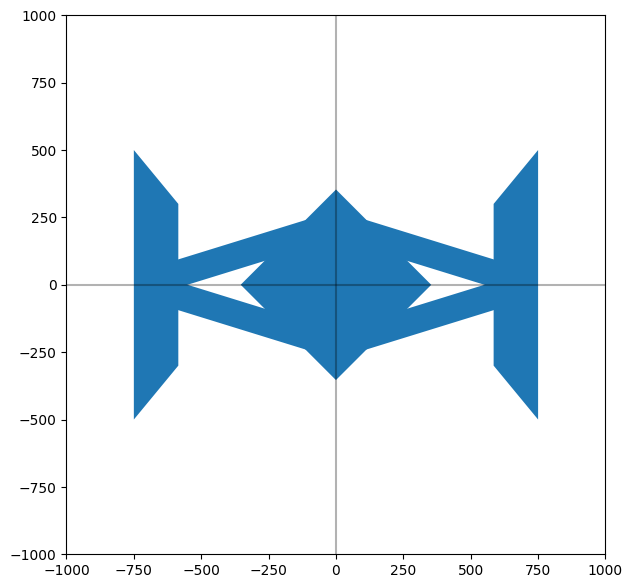

In [1459]:
# 그림판 선언 및 크기 설정
fig, ax = plt.subplots(figsize=(7,7))

# 축 그리기
draw_axis(ax)

# 물체 그리기
draw_object(ax)

plt.show()